# Medical Insurance Cost Prediction using Regression

**Goal:** predict individual medical insurance `charges` from `age`, `sex`, `bmi`, `children`, `smoker`, `region`.

**Workflow**
1. Load data & EDA
2. Hypothesis testing & multicollinearity analysis
3. Stratified train/test split, **engineered interaction features** and preprocessing pipeline
4. Compare Linear / Ridge / Lasso / ElasticNet / KNN / Random Forest / Gradient Boosting with **repeated cross-validation on the training set only** (raw vs engineered features, original vs log target)
5. Tune the candidates, estimate honest performance with **nested CV**, pick the winner from CV scores
6. Evaluate the winner on the held-out test set **once**, with bootstrap confidence intervals + residual analysis
7. Interpret important predictors & document findings

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, KFold, RepeatedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge, ElasticNet, LassoCV, ElasticNetCV
from sklearn.preprocessing import PolynomialFeatures
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from statsmodels.stats.outliers_influence import variance_inflation_factor

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

## 1. Load data & exploratory data analysis

In [2]:
from pathlib import Path

DATA_PATH = Path("../data/insurance.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("data/insurance.csv")  # if the kernel cwd is the project root

df = pd.read_csv(DATA_PATH)
print("Loaded:", DATA_PATH.resolve())
print("Shape:", df.shape)
df.head()

Loaded: D:\medical_insurance_cost_prediction\data\insurance.csv
Shape: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
print(df.info())
print("\nMissing values:\n", df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB
None

Missing values:
 age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64
Duplicate rows: 1


,count,mean,std,min,25%,50%,75%,max
age,1338.0,39.207025,14.049960,18.0000,27.00000,39.000,51.000000,64.00000
bmi,1338.0,30.663397,6.098187,15.9600,26.29625,30.400,34.693750,53.13000
children,1338.0,1.094918,1.205493,0.0000,0.00000,1.000,2.000000,5.00000
charges,1338.0,13270.422265,12110.011237,1121.8739,4740.28715,9382.033,16639.912515,63770.42801


In [4]:
# Exact duplicate rows add no information and can leak between train/test, so drop them
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after dropping duplicates:", df.shape)

Shape after dropping duplicates: (1337, 7)


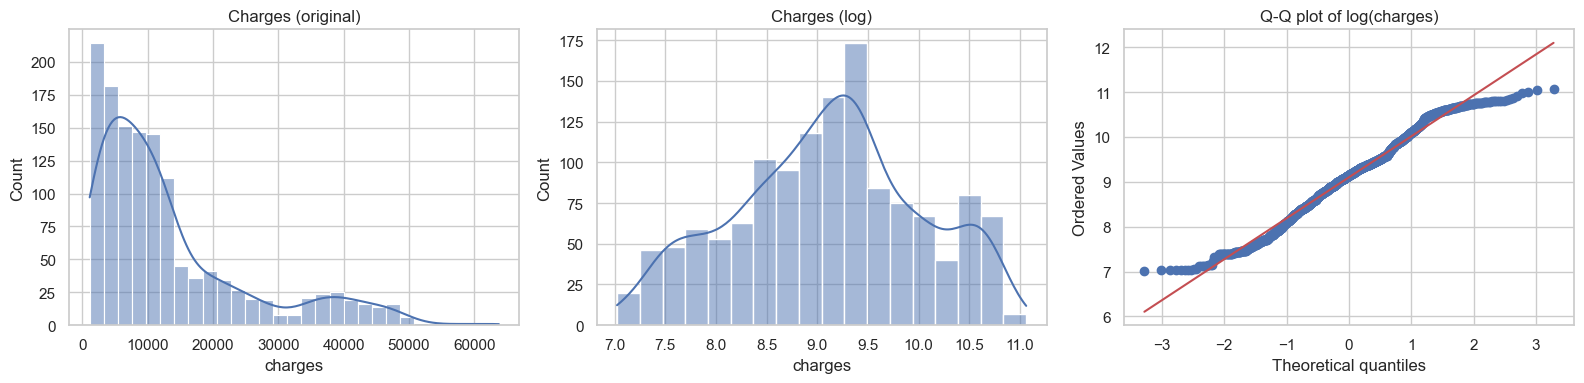

Skewness  original: 1.52 | log: -0.09


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df["charges"], kde=True, ax=axes[0]);            axes[0].set_title("Charges (original)")
sns.histplot(np.log(df["charges"]), kde=True, ax=axes[1]);    axes[1].set_title("Charges (log)")
stats.probplot(np.log(df["charges"]), plot=axes[2]);          axes[2].set_title("Q-Q plot of log(charges)")
plt.tight_layout(); plt.show()
print("Skewness  original:", round(df["charges"].skew(), 2), "| log:", round(np.log(df["charges"]).skew(), 2))

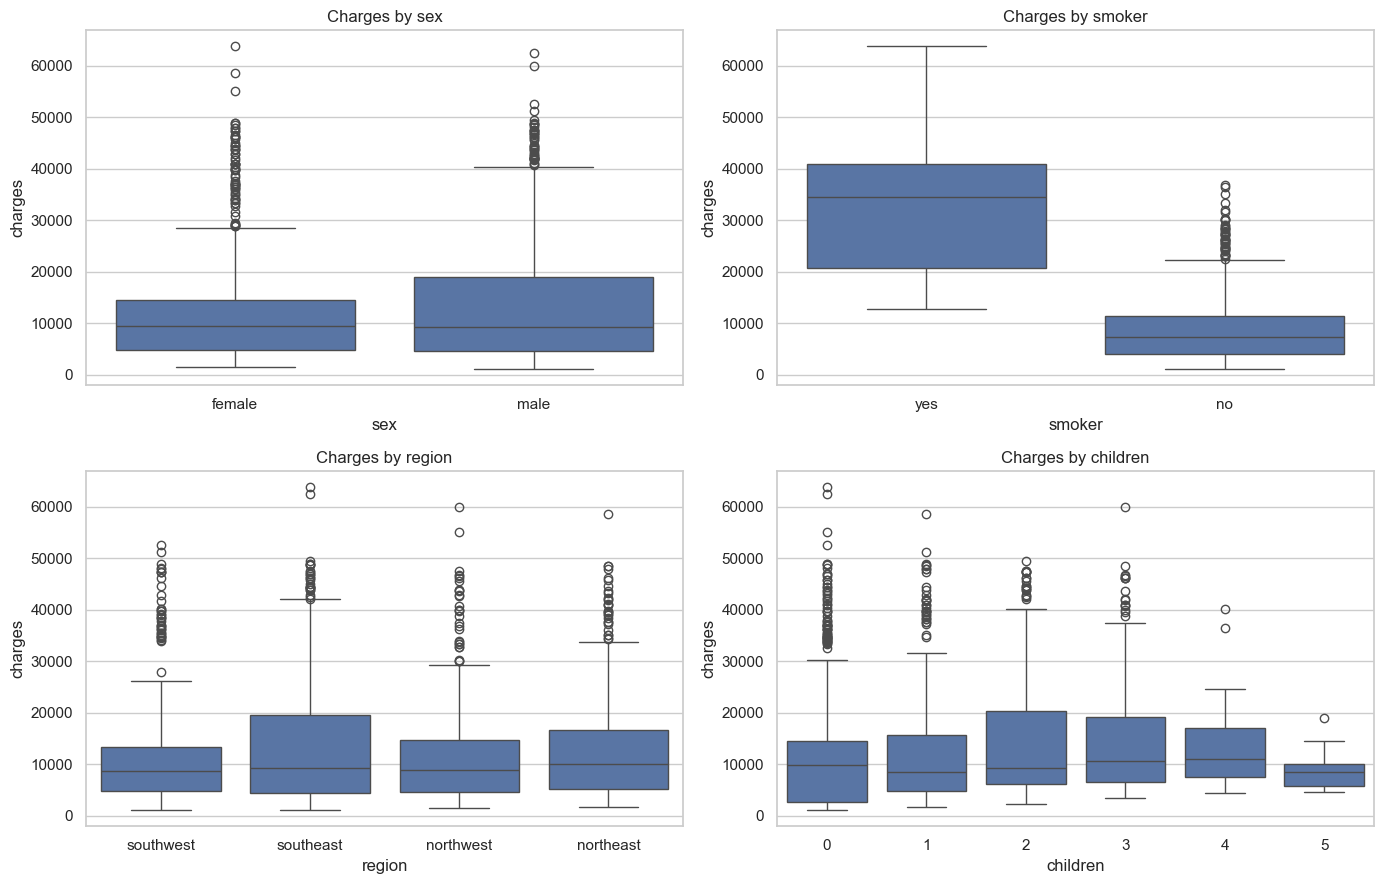

In [6]:
cat_cols = ["sex", "smoker", "region", "children"]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, c in zip(axes.ravel(), cat_cols):
    sns.boxplot(data=df, x=c, y="charges", ax=ax)
    ax.set_title(f"Charges by {c}")
plt.tight_layout(); plt.show()

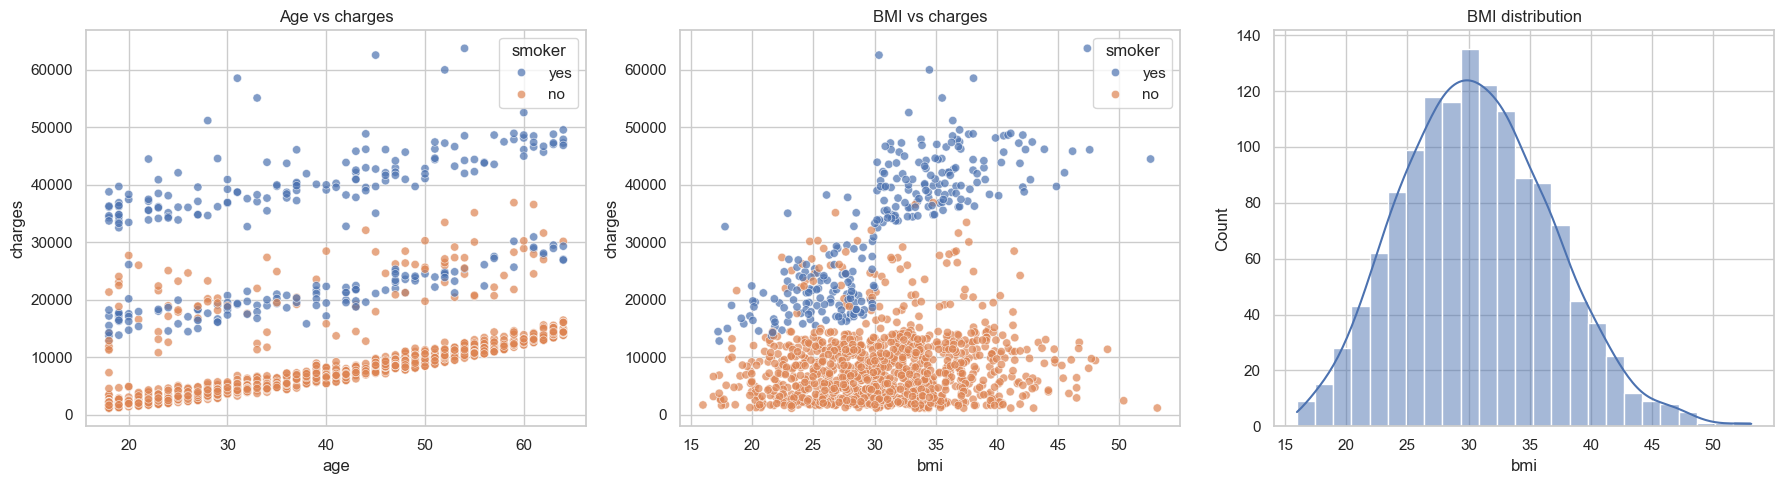

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.scatterplot(data=df, x="age", y="charges", hue="smoker", alpha=.7, ax=axes[0])
sns.scatterplot(data=df, x="bmi", y="charges", hue="smoker", alpha=.7, ax=axes[1])
sns.histplot(df["bmi"], kde=True, ax=axes[2])
axes[0].set_title("Age vs charges"); axes[1].set_title("BMI vs charges"); axes[2].set_title("BMI distribution")
plt.tight_layout(); plt.show()

**Things to notice:** charges are strongly right-skewed; smokers form a clearly separate (higher) cost band;
the BMI-vs-charges plot suggests an **interaction** (smokers with BMI ≥ 30 pay much more). Keep this in mind when we look at the residuals.

## 2. Hypothesis testing

In [8]:
alpha = 0.05
rows = []

# 1) Smoker vs non-smoker (Welch t-test + Mann-Whitney as non-parametric check)
s, n = df.loc[df.smoker=="yes","charges"], df.loc[df.smoker=="no","charges"]
t, p = stats.ttest_ind(s, n, equal_var=False);  u, pu = stats.mannwhitneyu(s, n)
rows.append(["Smoker vs non-smoker", "Welch t-test", t, p, "Mann-Whitney", pu])

# 2) Male vs female
m, f = df.loc[df.sex=="male","charges"], df.loc[df.sex=="female","charges"]
t, p = stats.ttest_ind(m, f, equal_var=False);  u, pu = stats.mannwhitneyu(m, f)
rows.append(["Male vs female", "Welch t-test", t, p, "Mann-Whitney", pu])

# 3) Region (4 groups): ANOVA + Kruskal-Wallis
groups = [g["charges"].values for _, g in df.groupby("region")]
F, p = stats.f_oneway(*groups);  H, pk = stats.kruskal(*groups)
rows.append(["Across regions", "ANOVA", F, p, "Kruskal-Wallis", pk])

# 4) Number of children: ANOVA + Kruskal-Wallis
groups = [g["charges"].values for _, g in df.groupby("children")]
F, p = stats.f_oneway(*groups);  H, pk = stats.kruskal(*groups)
rows.append(["Across # children", "ANOVA", F, p, "Kruskal-Wallis", pk])

# 5) Age & BMI vs charges: Pearson + Spearman
for v in ["age", "bmi"]:
    r, p = stats.pearsonr(df[v], df["charges"]);  rho, ps = stats.spearmanr(df[v], df["charges"])
    rows.append([f"{v} vs charges (r={r:.2f}, rho={rho:.2f})", "Pearson", r, p, "Spearman", ps])

# 6) BMI: obese (>=30) vs not, in the whole sample and within smokers
df["obese"] = (df["bmi"] >= 30).astype(int)
for label, sub in [("Obese vs non-obese (all)", df), ("Obese vs non-obese (smokers)", df[df.smoker=="yes"]),
                   ("Obese vs non-obese (non-smokers)", df[df.smoker=="no"])]:
    a, b = sub.loc[sub.obese==1,"charges"], sub.loc[sub.obese==0,"charges"]
    t, p = stats.ttest_ind(a, b, equal_var=False);  u, pu = stats.mannwhitneyu(a, b)
    rows.append([label, "Welch t-test", t, p, "Mann-Whitney", pu])

res = pd.DataFrame(rows, columns=["Question", "Test", "Statistic", "p-value", "Non-param test", "p-value (np)"])
res["Significant (α=0.05)"] = np.where((res["p-value"] < alpha) & (res["p-value (np)"] < alpha), "Yes",
                              np.where((res["p-value"] < alpha) | (res["p-value (np)"] < alpha), "Mixed", "No"))
res.style.format({"Statistic": "{:.2f}", "p-value": "{:.2e}", "p-value (np)": "{:.2e}"})

,Question,Test,Statistic,p-value,Non-param test,p-value (np),Significant (α=0.05)
0,Smoker vs non-smoker,Welch t-test,32.74,6.26e-103,Mann-Whitney,5.75e-130,Yes
1,Male vs female,Welch t-test,2.13,3.36e-02,Mann-Whitney,6.94e-01,Mixed
2,Across regions,ANOVA,2.93,3.28e-02,Kruskal-Wallis,2.02e-01,Mixed
3,Across # children,ANOVA,3.27,6.13e-03,Kruskal-Wallis,2.20e-05,Yes
4,"age vs charges (r=0.30, rho=0.53)",Pearson,0.30,6.98e-29,Spearman,3.19e-99,Yes
5,"bmi vs charges (r=0.20, rho=0.12)",Pearson,0.20,2.47e-13,Spearman,1.16e-05,Yes
6,Obese vs non-obese (all),Welch t-test,7.71,2.88e-14,Mann-Whitney,8.98e-05,Yes
7,Obese vs non-obese (smokers),Welch t-test,30.11,1.88e-88,Mann-Whitney,1.08e-44,Yes
8,Obese vs non-obese (non-smokers),Welch t-test,2.40,1.67e-02,Mann-Whitney,4.56e-03,Yes


**Reading the table:** a *Mixed* result means the parametric and non-parametric tests disagree (usually because charges are heavily skewed, so the t-test/ANOVA assumptions are shaky).
The obesity test **within smokers vs non-smokers** is the key one: if BMI only matters for smokers, that is an interaction effect that a plain linear model cannot capture.

## 3. Multicollinearity analysis

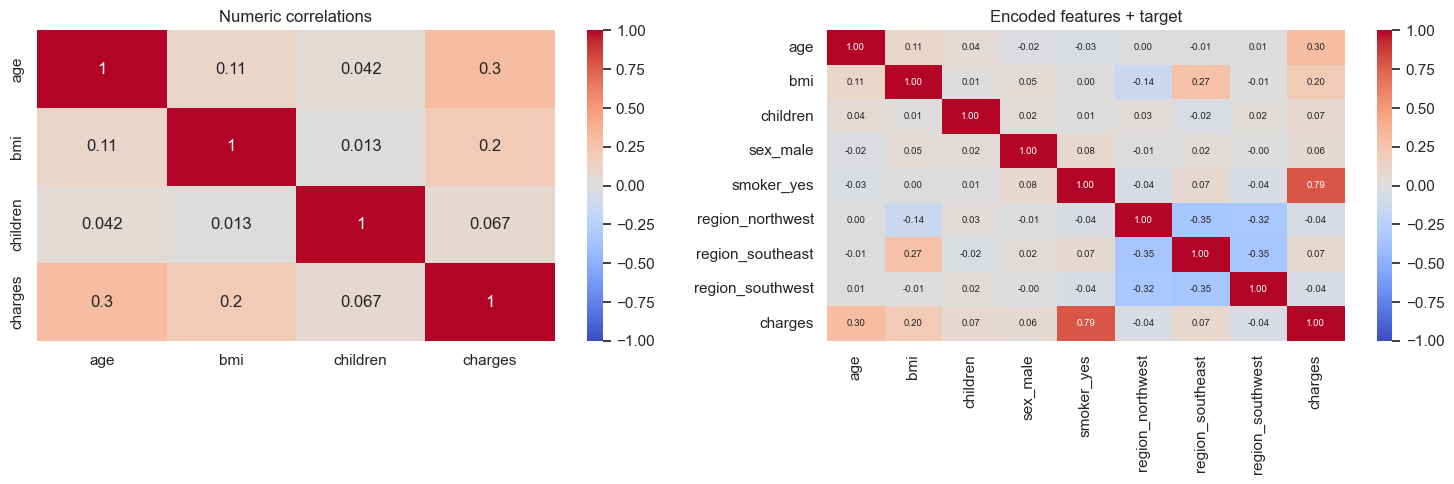

,feature,VIF
6,region_southeast,1.651779
7,region_southwest,1.529044
5,region_northwest,1.517673
1,bmi,1.106742
0,age,1.016794
4,smoker_yes,1.012100
3,sex_male,1.008944
2,children,1.004017


In [9]:
num = df[["age", "bmi", "children", "charges"]]
X_enc = pd.get_dummies(df[["age","sex","bmi","children","smoker","region"]], drop_first=True).astype(float)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(num.corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0]); axes[0].set_title("Numeric correlations")
sns.heatmap(pd.concat([X_enc, df["charges"]], axis=1).corr(), annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, ax=axes[1], annot_kws={"size": 7}); axes[1].set_title("Encoded features + target")
plt.tight_layout(); plt.show()

# VIF (add a constant so VIF is computed correctly)
Xc = X_enc.copy(); Xc.insert(0, "const", 1.0)
vif = pd.DataFrame({"feature": Xc.columns[1:],
                    "VIF": [variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])]}).sort_values("VIF", ascending=False)
vif

Rule of thumb: VIF < 5 is fine, 5–10 is moderate, > 10 is a problem. Multicollinearity matters most for the linear models' coefficient interpretation; tree models are largely immune.

## 4. Train/test split & preprocessing pipeline

In [10]:
X = df.drop(columns=["charges", "obese"])
y = df["charges"]

# Stratify on smoker (dominant driver, ~20% of rows) so both splits have the same smoker proportion
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=X["smoker"])
print(X_train.shape, X_test.shape)
print("Smoker share  train:", (X_train.smoker=="yes").mean().round(3), "| test:", (X_test.smoker=="yes").mean().round(3))

# ---- Engineered features: smoking x BMI is the key pattern (obesity matters a lot for smokers, hardly for non-smokers)
def add_features(d):
    d = d.copy()
    s = (d["smoker"] == "yes").astype(int)
    d["obese"]          = (d["bmi"] >= 30).astype(int)
    d["smoker_x_bmi"]   = s * d["bmi"]
    d["smoker_x_obese"] = s * d["obese"]
    d["smoker_x_age"]   = s * d["age"]
    return d

base_num = ["age", "bmi", "children"]
eng_num  = ["smoker_x_bmi", "smoker_x_age"]
eng_bin  = ["obese", "smoker_x_obese"]
cat_features = ["sex", "smoker", "region"]

def make_preprocessor(engineered=False):
    num = base_num + (eng_num if engineered else [])
    tfs = [("num", StandardScaler(), num),
           ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_features)]
    if engineered:
        tfs.append(("bin", "passthrough", eng_bin))
    return ColumnTransformer(tfs)

(1069, 6) (268, 6)
Smoker share  train: 0.205 | test: 0.205


## 5. Regression models + cross-validation

In [11]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge":             Ridge(alpha=1.0),
    "Lasso":             LassoCV(cv=5, max_iter=50000, random_state=RANDOM_STATE),
    "ElasticNet":        ElasticNetCV(l1_ratio=[.1, .5, .7, .9, .95, 1], cv=5, max_iter=50000, random_state=RANDOM_STATE),
    "KNN":               KNeighborsRegressor(n_neighbors=7),
    "Random Forest":     RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=200, max_depth=2, learning_rate=0.05, random_state=RANDOM_STATE),
}

# Regularised linear models on automatic pairwise interaction terms (raw features only)
def with_interactions(est):
    return Pipeline([("poly", PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)),
                     ("scale", StandardScaler()), ("est", est)])
poly_models = {
    "Lasso + poly interactions": with_interactions(LassoCV(cv=5, max_iter=50000, random_state=RANDOM_STATE)),
    "ElasticNet + poly interactions": with_interactions(
        ElasticNetCV(l1_ratio=[.1, .5, .7, .9, .95, 1], cv=5, max_iter=50000, random_state=RANDOM_STATE)),
}

def build(model, log_target=False, engineered=False):
    """Raw DataFrame in -> [feature engineering] -> preprocessing -> model."""
    steps = []
    if engineered:
        steps.append(("fe", FunctionTransformer(add_features)))
    steps += [("prep", make_preprocessor(engineered)), ("model", model)]
    pipe = Pipeline(steps)
    if log_target:
        return TransformedTargetRegressor(regressor=pipe, func=np.log, inverse_func=np.exp)
    return pipe

scoring = {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error", "R2": "r2"}
kf  = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)                     # used for tuning
rkf = RepeatedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)             # used for comparison (15 scores each)

# Selection happens on the TRAINING set only. Every candidate: raw vs engineered features, original vs log target.
candidates = [(n, m, f) for n, m in models.items() for f in (False, True)] + \
             [(n, m, False) for n, m in poly_models.items()]
rows = []
for target in ["Original", "Log"]:
    for name, mdl, eng in candidates:
        cv = cross_validate(build(mdl, target == "Log", eng), X_train, y_train, cv=rkf, scoring=scoring, n_jobs=-1)
        rows.append({"Target": target, "Model": name, "Features": "Engineered" if eng else "Raw",
                     "MAE": -cv["test_MAE"].mean(),  "MAE_sd": cv["test_MAE"].std(),
                     "RMSE": -cv["test_RMSE"].mean(), "RMSE_sd": cv["test_RMSE"].std(),
                     "R2": cv["test_R2"].mean(),     "R2_sd": cv["test_R2"].std()})
cv_results = pd.DataFrame(rows)
cv_results["Candidate"] = cv_results["Model"] + " [" + cv_results["Features"].str[:3] + "]"
cv_results.sort_values(["Target", "RMSE"]).round(3)

,Target,Model,Features,MAE,MAE_sd,RMSE,RMSE_sd,R2,R2_sd,Candidate
26,Log,Random Forest,Raw,2331.692,261.794,4818.060,547.956,0.837,0.039,Random Forest [Raw]
27,Log,Random Forest,Engineered,2340.440,266.118,4837.248,556.314,0.836,0.039,Random Forest [Eng]
25,Log,KNN,Engineered,2437.629,244.686,4884.718,541.067,0.833,0.040,KNN [Eng]
29,Log,Gradient Boosting,Engineered,2429.187,246.976,4981.410,495.007,0.827,0.035,Gradient Boosting [Eng]
28,Log,Gradient Boosting,Raw,2504.750,265.592,5072.801,520.100,0.821,0.035,Gradient Boosting [Raw]
17,Log,Linear Regression,Engineered,2666.906,268.155,5193.401,539.792,0.811,0.046,Linear Regression [Eng]
21,Log,Lasso,Engineered,2662.789,271.452,5206.421,552.681,0.810,0.046,Lasso [Eng]
23,Log,ElasticNet,Engineered,2662.789,271.452,5206.421,552.681,0.810,0.046,ElasticNet [Eng]
19,Log,Ridge,Engineered,2724.045,285.762,5374.301,562.865,0.797,0.048,Ridge [Eng]
31,Log,ElasticNet + poly interactions,Raw,2821.084,288.022,5382.858,614.035,0.798,0.046,ElasticNet + poly interactions [Raw]


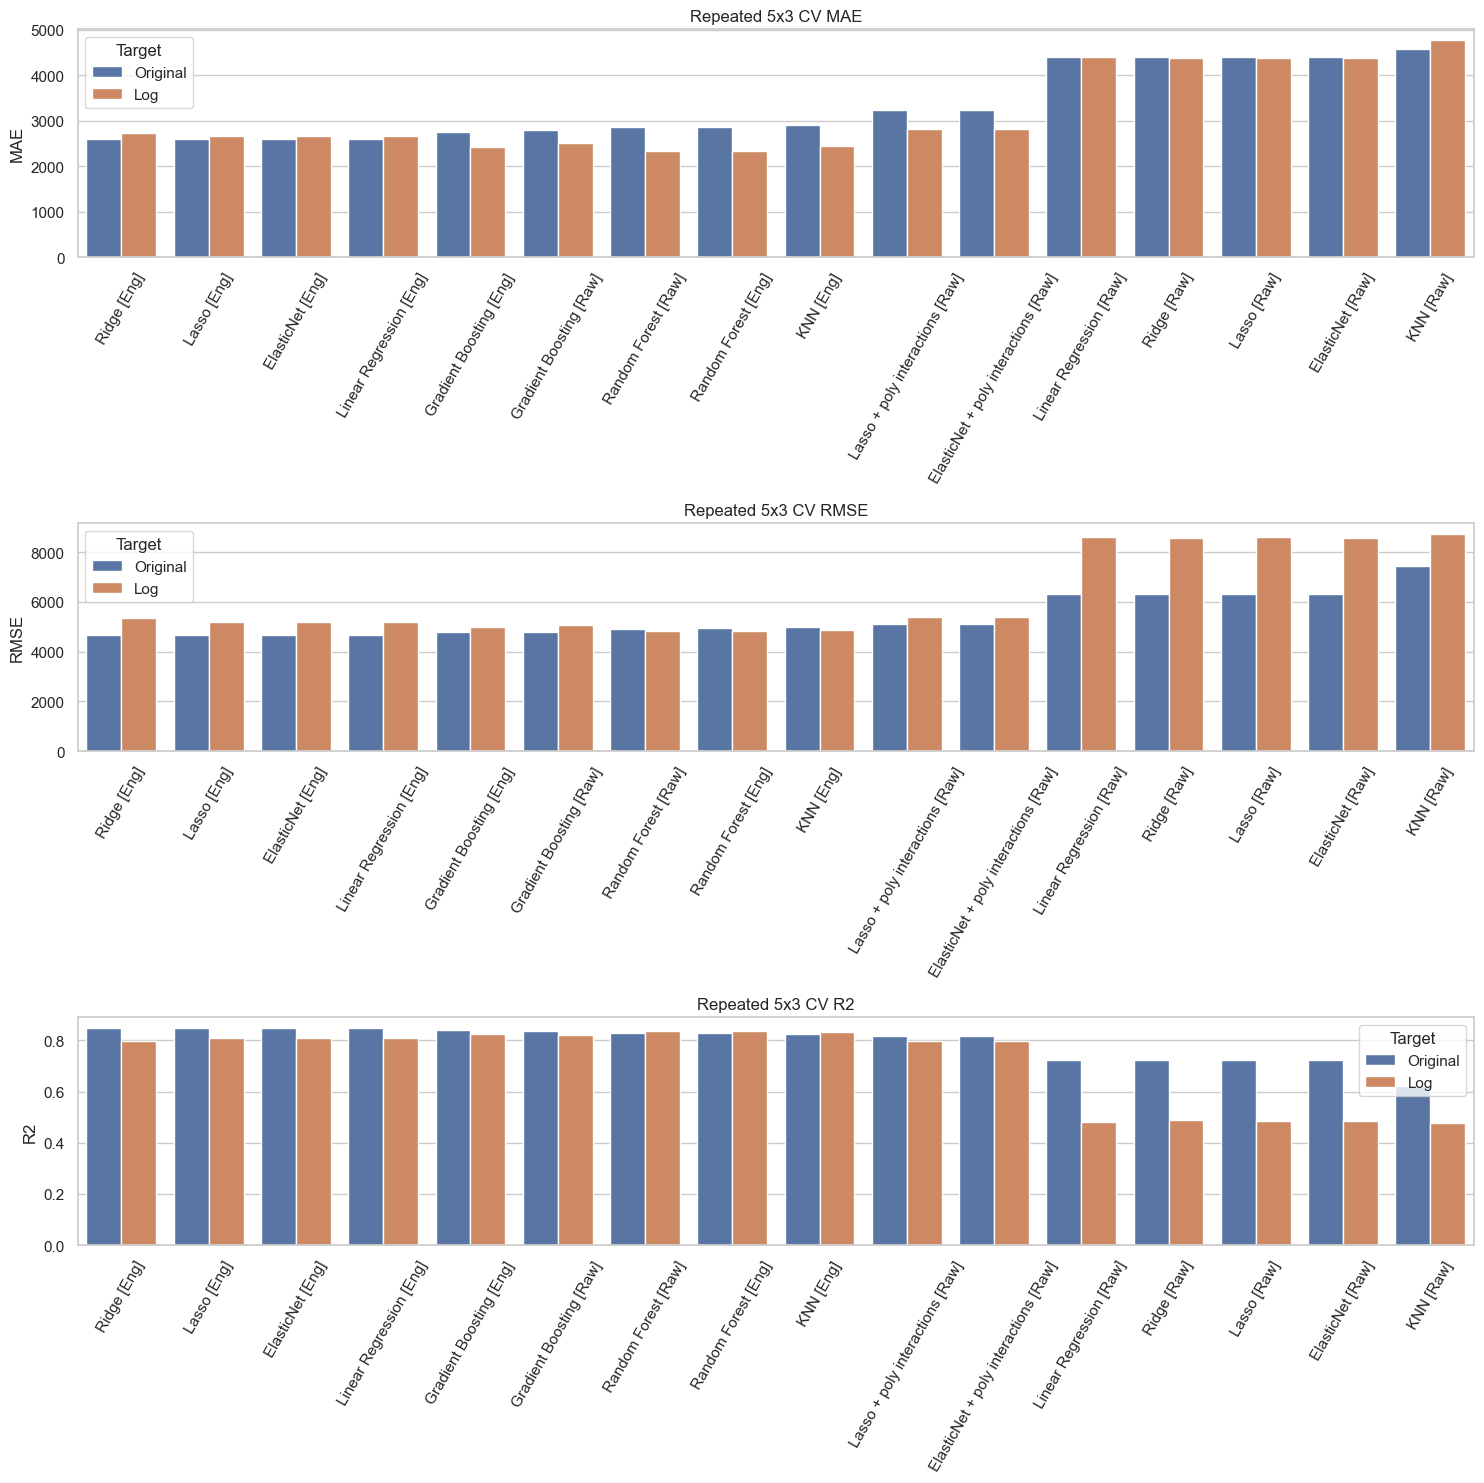

In [12]:
# Original vs log target, raw vs engineered features (5x3 repeated CV, error bars = SD across the 15 folds)
fig, axes = plt.subplots(3, 1, figsize=(15, 15))
order = cv_results[cv_results.Target == "Original"].sort_values("RMSE")["Candidate"]
for ax, metric in zip(axes, ["MAE", "RMSE", "R2"]):
    sns.barplot(data=cv_results, x="Candidate", y=metric, hue="Target", order=order, ax=ax)
    ax.set_title(f"Repeated 5x3 CV {metric}"); ax.tick_params(axis="x", rotation=60); ax.set_xlabel("")
plt.tight_layout(); plt.show()

**Reading the comparison:**
* *Engineered features* (`obese`, `smoker x bmi`, `smoker x obese`, `smoker x age`) give the linear family the smoker x BMI pattern that otherwise only trees capture.
* *Log target:* a model trained on `log(charges)` and back-transformed optimises *relative* error. It fixes skew/heteroscedasticity but can *hurt* MAE/RMSE in dollars because large charges are under-weighted. We compare both rather than assume.

### Tune the candidates

In [13]:
print("Best untuned CV result per feature set (original target):")
print(cv_results[cv_results.Target == "Original"].sort_values("RMSE").groupby("Features").head(3)
      [["Model", "Features", "RMSE", "RMSE_sd", "MAE", "R2"]].round(3).to_string(index=False))
print("\nMean CV RMSE gain from engineered features, linear family (Original target):")
lin = cv_results[(cv_results.Target == "Original") & cv_results.Model.isin(["Linear Regression", "Ridge", "Lasso", "ElasticNet"])]
print(lin.pivot(index="Model", columns="Features", values="RMSE").round(0))

Best untuned CV result per feature set (original target):
                    Model   Features     RMSE  RMSE_sd      MAE    R2
                    Ridge Engineered 4660.738  529.650 2598.574 0.848
                    Lasso Engineered 4661.061  528.305 2597.426 0.848
               ElasticNet Engineered 4661.061  528.305 2597.426 0.848
        Gradient Boosting        Raw 4807.664  491.521 2790.598 0.839
            Random Forest        Raw 4929.500  501.642 2848.184 0.830
Lasso + poly interactions        Raw 5109.604  525.240 3227.285 0.818

Mean CV RMSE gain from engineered features, linear family (Original target):
Features           Engineered     Raw
Model                                
ElasticNet             4661.0  6327.0
Lasso                  4661.0  6327.0
Linear Regression      4661.0  6319.0
Ridge                  4661.0  6319.0


In [14]:
# Hyper-parameter tuning on the training set (original target, engineered features).
# Ridge/ElasticNet get a wide alpha grid; l1_ratio=1 is Lasso.
grids = {
    "Ridge": (Ridge(), {"model__alpha": np.logspace(-3, 3, 13)}),
    "ElasticNet": (ElasticNet(max_iter=50000),
        {"model__alpha": np.logspace(-3, 2, 11), "model__l1_ratio": [0.05, 0.2, 0.5, 0.8, 0.95, 1.0]}),
    "Gradient Boosting": (GradientBoostingRegressor(random_state=RANDOM_STATE),
        {"model__n_estimators": [100, 200, 300], "model__max_depth": [2, 3, 4],
         "model__learning_rate": [0.03, 0.05, 0.1], "model__min_samples_leaf": [5, 10, 20]}),
    "Random Forest": (RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
        {"model__n_estimators": [300], "model__max_depth": [4, 6, 8, None], "model__min_samples_leaf": [3, 5, 10]}),
}
tuned = {}
for name, (est, grid) in grids.items():
    gs = GridSearchCV(build(est, engineered=True), grid, cv=kf, scoring="neg_root_mean_squared_error", n_jobs=-1)
    gs.fit(X_train, y_train)
    tuned[name] = gs
    print(f"{name:18s} best CV RMSE = {-gs.best_score_:,.1f} | {gs.best_params_}")

Ridge              best CV RMSE = 4,656.6 | {'model__alpha': np.float64(1.0)}
ElasticNet         best CV RMSE = 4,648.5 | {'model__alpha': np.float64(31.622776601683793), 'model__l1_ratio': 1.0}
Gradient Boosting  best CV RMSE = 4,711.6 | {'model__learning_rate': 0.03, 'model__max_depth': 2, 'model__min_samples_leaf': 20, 'model__n_estimators': 300}
Random Forest      best CV RMSE = 4,773.4 | {'model__max_depth': 6, 'model__min_samples_leaf': 5, 'model__n_estimators': 300}


In [15]:
# How do the regularised models treat the coefficients? (numeric features standardised -> comparable)
feat_names = tuned["Ridge"].best_estimator_.named_steps["prep"].get_feature_names_out()
lin_ols = build(LinearRegression(), engineered=True).fit(X_train, y_train)
coef_tbl = pd.DataFrame({
    "OLS":        lin_ols.named_steps["model"].coef_,
    "Ridge":      tuned["Ridge"].best_estimator_.named_steps["model"].coef_,
    "ElasticNet": tuned["ElasticNet"].best_estimator_.named_steps["model"].coef_,
}, index=feat_names).round(1)
coef_tbl

,OLS,Ridge,ElasticNet
num__age,3640.5,3635.3,3587.7
num__bmi,-99.2,-115.6,0.0
num__children,721.5,720.5,686.4
num__smoker_x_bmi,6826.2,7044.3,6698.3
num__smoker_x_age,-150.3,-141.8,0.0
cat__sex_male,-693.8,-687.2,-556.1
cat__smoker_yes,-183.8,-460.1,0.0
cat__region_northwest,-451.0,-442.2,-0.0
cat__region_southeast,-881.2,-873.3,-422.1
cat__region_southwest,-1510.0,-1483.5,-1001.9


## 6. Model selection (CV only) and one-shot test evaluation

In [16]:
# ---- Selection uses CV scores only. The test set has not been touched yet.
final_name = max(tuned, key=lambda k: tuned[k].best_score_)
final_model = tuned[final_name].best_estimator_
print("Selected model:", final_name, "| tuned CV RMSE = %.0f" % -tuned[final_name].best_score_)

# Honest performance estimate: NESTED CV (inner loop re-tunes on each outer training fold)
est, grid = grids[final_name]
outer = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE + 1)
inner = GridSearchCV(build(est, engineered=True), grid, cv=KFold(3, shuffle=True, random_state=RANDOM_STATE),
                     scoring="neg_root_mean_squared_error", n_jobs=-1)
nested = cross_validate(inner, X_train, y_train, cv=outer, scoring=scoring)
print("Nested CV (5 outer folds)  RMSE = %.0f +/- %.0f | MAE = %.0f +/- %.0f | R2 = %.3f +/- %.3f" % (
    -nested["test_RMSE"].mean(), nested["test_RMSE"].std(), -nested["test_MAE"].mean(), nested["test_MAE"].std(),
    nested["test_R2"].mean(), nested["test_R2"].std()))

# ---- Single evaluation on the held-out test set + bootstrap 95% CI (resampling the 268 test rows)
def metrics(y_, p_):
    return np.array([mean_absolute_error(y_, p_), np.sqrt(mean_squared_error(y_, p_)), r2_score(y_, p_)])

pred = final_model.predict(X_test)
point = metrics(y_test.values, pred)
rng = np.random.default_rng(RANDOM_STATE)
boot = np.array([metrics(y_test.values[i], pred[i]) for i in (rng.integers(0, len(pred), len(pred)) for _ in range(2000))])
lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)
test_ci = pd.DataFrame({"Test": point, "95% CI low": lo, "95% CI high": hi}, index=["MAE", "RMSE", "R2"])
print(f"\nHeld-out test ({final_name}, n={len(y_test)}):")
test_ci.round(3)

Selected model: ElasticNet | tuned CV RMSE = 4648
Nested CV (5 outer folds)  RMSE = 4672 +/- 455 | MAE = 2603 +/- 192 | R2 = 0.849 +/- 0.024

Held-out test (ElasticNet, n=268):


,Test,95% CI low,95% CI high
MAE,1995.715,1700.012,2336.200
RMSE,3343.332,2572.465,4108.482
R2,0.922,0.879,0.955


In [17]:
resid = y_test.values - pred
print(f"{final_name} -> test MAE: {point[0]:,.0f} | RMSE: {point[1]:,.0f} | R²: {point[2]:.3f}")
print("Reminder: a single split of ~268 rows is noisy - compare with the CV / nested-CV numbers above, not just this one.")

ElasticNet -> test MAE: 1,996 | RMSE: 3,343 | R²: 0.922
Reminder: a single split of ~268 rows is noisy - compare with the CV / nested-CV numbers above, not just this one.


### Residual analysis

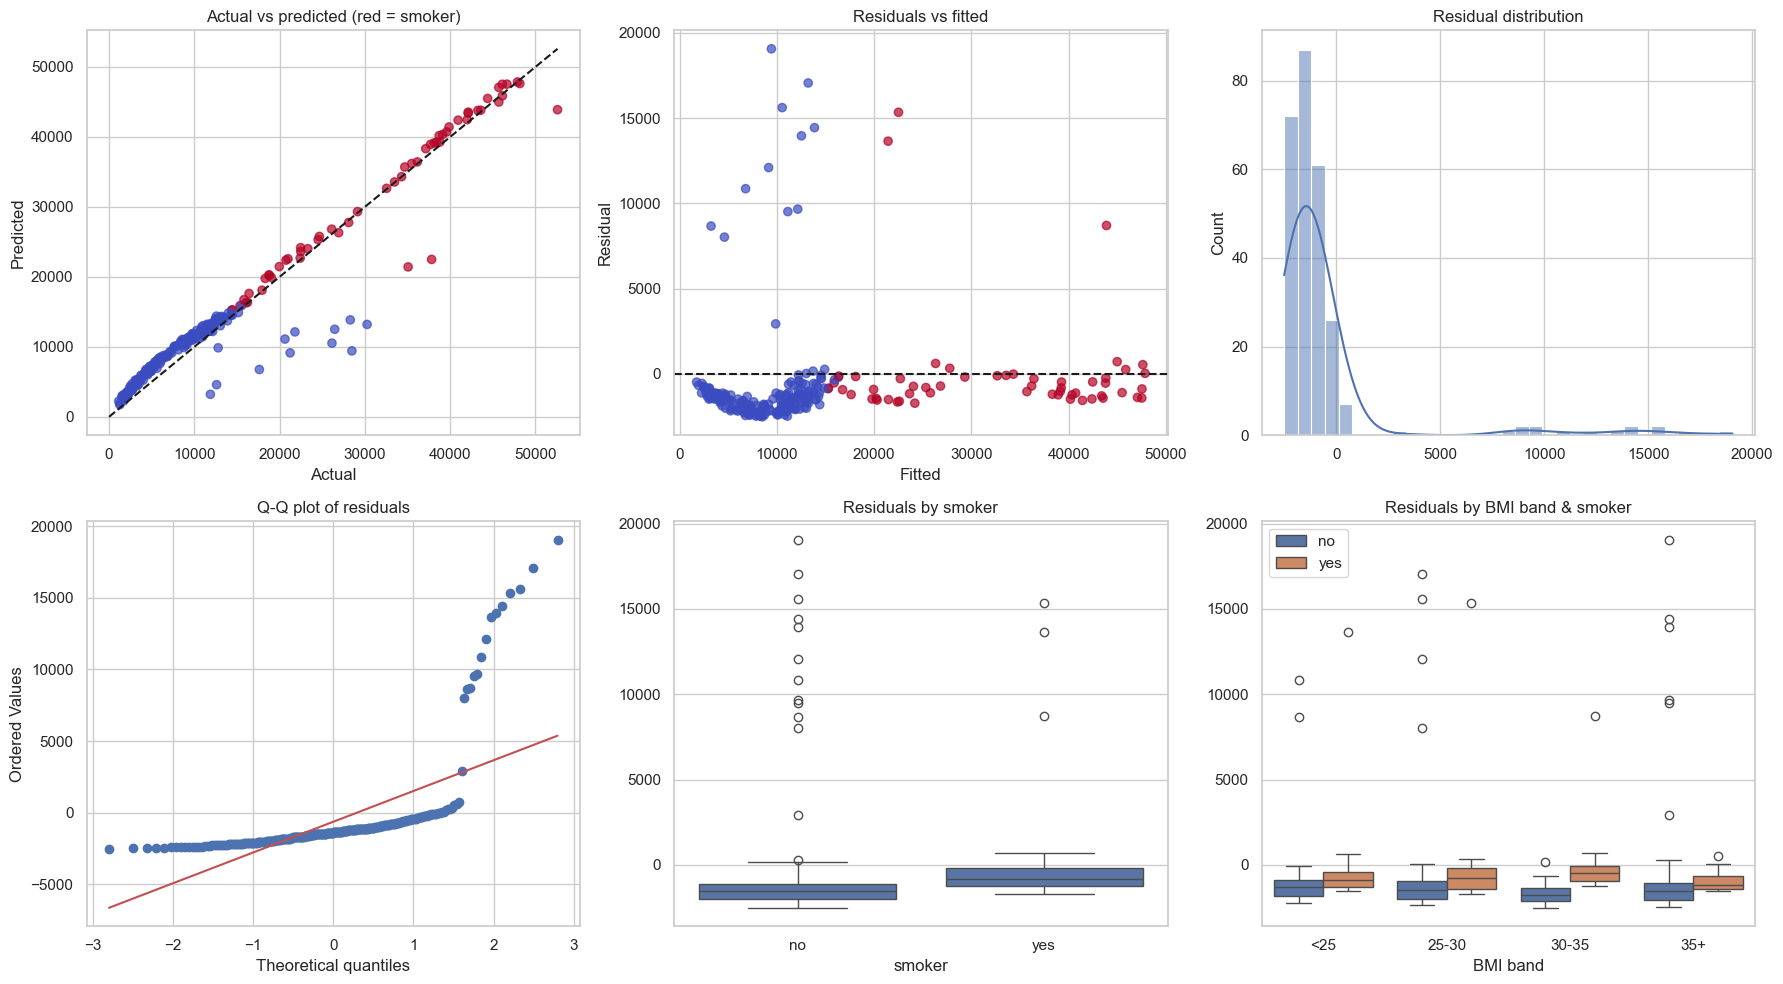

Residual mean: -633.6 | skew: 4.08
Shapiro-Wilk p-value (residual normality): 2.09e-28
Spearman |resid| vs fitted (heteroscedasticity check): rho = -0.31


In [18]:
smoker = X_test["smoker"].values
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

axes[0,0].scatter(y_test, pred, c=(smoker=="yes"), cmap="coolwarm", alpha=.7)
lim = [0, max(y_test.max(), pred.max())]; axes[0,0].plot(lim, lim, "k--")
axes[0,0].set(title="Actual vs predicted (red = smoker)", xlabel="Actual", ylabel="Predicted")

axes[0,1].scatter(pred, resid, c=(smoker=="yes"), cmap="coolwarm", alpha=.7); axes[0,1].axhline(0, color="k", ls="--")
axes[0,1].set(title="Residuals vs fitted", xlabel="Fitted", ylabel="Residual")

sns.histplot(resid, kde=True, ax=axes[0,2]); axes[0,2].set_title("Residual distribution")

stats.probplot(resid, plot=axes[1,0]); axes[1,0].set_title("Q-Q plot of residuals")

sns.boxplot(x=smoker, y=resid, ax=axes[1,1]); axes[1,1].set(title="Residuals by smoker", xlabel="smoker")

bmi_bins = pd.cut(X_test["bmi"].values, [0, 25, 30, 35, 60], labels=["<25", "25-30", "30-35", "35+"])
sns.boxplot(x=bmi_bins, y=resid, hue=smoker, ax=axes[1,2]); axes[1,2].set(title="Residuals by BMI band & smoker", xlabel="BMI band")
plt.tight_layout(); plt.show()

print("Residual mean:", round(resid.mean(), 1), "| skew:", round(stats.skew(resid), 2))
print("Shapiro-Wilk p-value (residual normality):", f"{stats.shapiro(resid)[1]:.2e}")
print("Spearman |resid| vs fitted (heteroscedasticity check): rho = %.2f" % stats.spearmanr(np.abs(resid), pred)[0])

In [19]:
# Where does the model make its biggest errors?
err = X_test.copy(); err["actual"] = y_test.values; err["pred"] = pred; err["abs_err"] = np.abs(resid)
print("MAE by group")
print(err.groupby("smoker")["abs_err"].mean().round(0).to_string())
print()
print(err.assign(bmi_band=bmi_bins).groupby(["smoker", "bmi_band"])["abs_err"].mean().round(0).to_string())
err.sort_values("abs_err", ascending=False).head(8).round(1)

MAE by group
smoker
no     2121.0
yes    1511.0

smoker  bmi_band
no      <25         1748.0
        25-30       2135.0
        30-35       1707.0
        35+         3007.0
yes     <25         2125.0
        25-30       1931.0
        30-35       1149.0
        35+         1032.0


,age,sex,bmi,children,smoker,region,actual,pred,abs_err
805,40,female,41.4,1,no,northwest,28476.7,9420.8,19056.0
115,60,male,28.6,0,no,northeast,30260.0,13205.1,17054.9
875,49,female,27.1,1,no,southwest,26140.4,10530.1,15610.2
1302,43,male,27.8,0,yes,southwest,37829.7,22494.7,15335.0
443,59,female,36.5,1,no,southeast,28287.9,13852.6,14435.3
963,52,male,36.8,2,no,northwest,26467.1,12511.3,13955.8
916,45,male,22.9,0,yes,northeast,35069.4,21425.4,13644.0
1002,48,male,29.6,0,no,southwest,21232.2,9137.6,12094.6


## 7. Interpreting important predictors

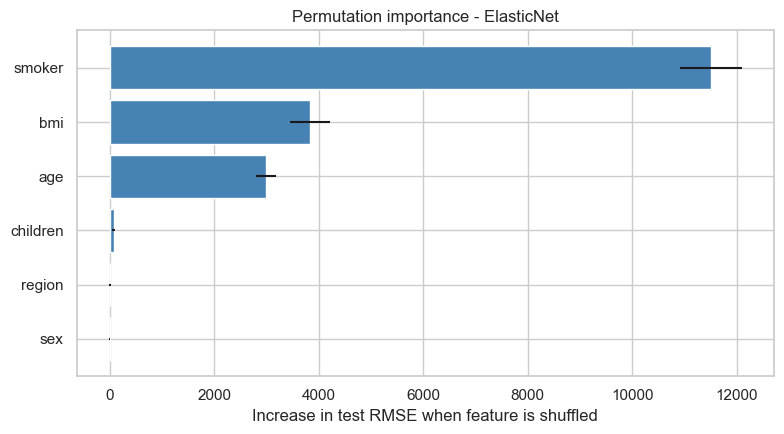

,feature,importance,sd
4,smoker,11502.6,600.2
2,bmi,3827.2,385.5
0,age,2993.6,191.5
3,children,76.0,35.3
5,region,4.0,24.4
1,sex,-1.4,16.7


In [20]:
# Permutation importance on the TEST set (model-agnostic, uses original column names)
pi = permutation_importance(final_model, X_test, y_test, n_repeats=30, random_state=RANDOM_STATE,
                            scoring="neg_root_mean_squared_error", n_jobs=-1)
imp = pd.DataFrame({"feature": X_test.columns, "importance": pi.importances_mean, "sd": pi.importances_std}) \
        .sort_values("importance", ascending=True)
plt.figure(figsize=(8, 4.5))
plt.barh(imp["feature"], imp["importance"], xerr=imp["sd"], color="steelblue")
plt.xlabel("Increase in test RMSE when feature is shuffled"); plt.title(f"Permutation importance - {final_name}")
plt.tight_layout(); plt.show()
imp.sort_values("importance", ascending=False).round(1)

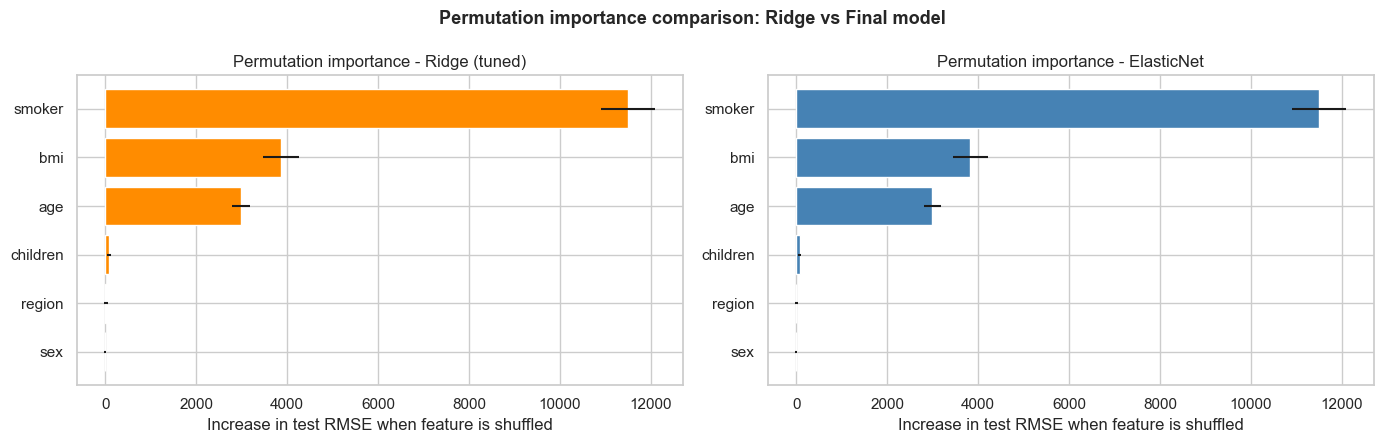

Ridge permutation importance (test set):


,feature,importance,sd
4,smoker,11498.3,603.9
2,bmi,3869.8,389.8
0,age,2992.1,195.5
3,children,82.8,37.2
5,region,14.6,34.2
1,sex,0.3,20.4


In [21]:
# Permutation importance on the TEST set for the tuned Ridge model
ridge_model = tuned["Ridge"].best_estimator_
pi_ridge = permutation_importance(
    ridge_model, X_test, y_test,
    n_repeats=30, random_state=RANDOM_STATE,
    scoring="neg_root_mean_squared_error", n_jobs=-1
)
imp_ridge = pd.DataFrame({
    "feature": X_test.columns,
    "importance": pi_ridge.importances_mean,
    "sd": pi_ridge.importances_std
}).sort_values("importance", ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Ridge
axes[0].barh(imp_ridge["feature"], imp_ridge["importance"], xerr=imp_ridge["sd"], color="darkorange")
axes[0].set_xlabel("Increase in test RMSE when feature is shuffled")
axes[0].set_title("Permutation importance - Ridge (tuned)")

# Final model (already computed above as `imp`)
axes[1].barh(imp["feature"], imp["importance"], xerr=imp["sd"], color="steelblue")
axes[1].set_xlabel("Increase in test RMSE when feature is shuffled")
axes[1].set_title(f"Permutation importance - {final_name}")

plt.suptitle("Permutation importance comparison: Ridge vs Final model", fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()

print("Ridge permutation importance (test set):")
imp_ridge.sort_values("importance", ascending=False).round(1)

In [22]:
# Interpretable view: a linear model on log(charges) gives approximate % effects
lin = build(LinearRegression(), log_target=True).fit(X_train, y_train)
names = lin.regressor_.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(lin.regressor_.named_steps["model"].coef_, index=names)
effects = pd.DataFrame({"coef (log scale)": coefs, "approx % change in charges": (np.exp(coefs) - 1) * 100}).round(3)
effects.sort_values("coef (log scale)", ascending=False)

,coef (log scale),approx % change in charges
cat__smoker_yes,1.552,372.213
num__age,0.479,61.453
num__children,0.126,13.472
num__bmi,0.076,7.886
cat__region_northwest,-0.061,-5.946
cat__sex_male,-0.086,-8.200
cat__region_southwest,-0.141,-13.181
cat__region_southeast,-0.183,-16.741


*(Numeric features are standardised, so their effect is per +1 standard deviation; dummy variables are relative to the dropped category.)*

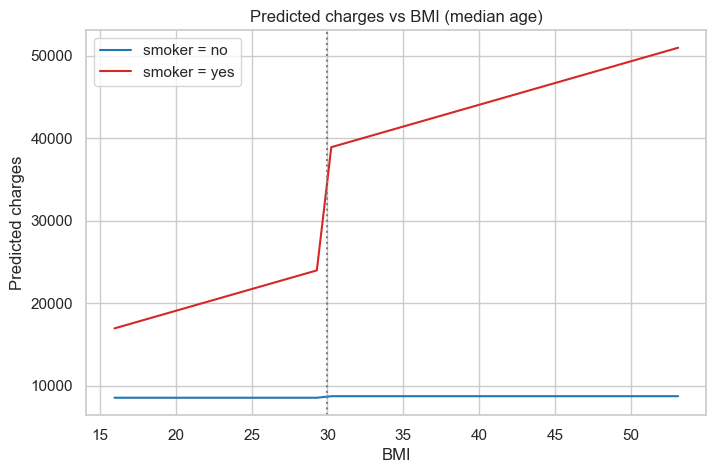

In [23]:
# Partial dependence-style look at the smoker x BMI interaction using the final model
bmi_grid = np.linspace(X_train.bmi.min(), X_train.bmi.max(), 40)
base = X_train.median(numeric_only=True)
plt.figure(figsize=(8, 5))
for s, col in [("no", "tab:blue"), ("yes", "tab:red")]:
    grid = pd.DataFrame({"age": base["age"], "sex": "female", "bmi": bmi_grid, "children": 1,
                         "smoker": s, "region": "southeast"})
    plt.plot(bmi_grid, final_model.predict(grid), color=col, label=f"smoker = {s}")
plt.axvline(30, color="gray", ls=":"); plt.xlabel("BMI"); plt.ylabel("Predicted charges")
plt.title("Predicted charges vs BMI (median age)"); plt.legend(); plt.show()

## 8. Findings & documentation

### Data
* 1,338 rows, 6 features, no missing values. One exact duplicate row was removed (1,337 remain).
* `charges` is right-skewed (skew ≈ 1.5); the log transform makes it near-symmetric (skew ≈ -0.1).

### Hypothesis tests (α = 0.05)
* **Smoker:** mean charges ≈ \$32,050 vs ≈ \$8,441 for non-smokers (p ≈ 1e-103). By far the strongest effect.
* **Obesity (BMI ≥ 30):** the effect is very large *among smokers* (≈ \$41.6k vs ≈ \$21.4k, p ≈ 1e-88) but small among non-smokers (≈ \$8.9k vs ≈ \$8.0k, p ≈ 0.02). BMI is mostly a cost driver *in combination with smoking*, i.e. an interaction.
* **Children:** significant on both tests (ANOVA p ≈ 0.006, Kruskal p ≈ 2e-5), but the effect is modest.
* **Sex and region:** parametric and non-parametric tests disagree (sex: t-test p ≈ 0.03 vs Mann-Whitney p ≈ 0.69; region: ANOVA p ≈ 0.03 vs Kruskal p ≈ 0.20), so the evidence is weak and not robust. Their effect is also negligible in the models.

### Multicollinearity
* All VIFs are below 1.7, so there is no multicollinearity problem; the linear model coefficients are stable and interpretable.
### Model comparison (5x3 repeated CV on the training set, untuned)
| Model | Raw features RMSE | Engineered features RMSE | Engineered + log target RMSE |
|---|---|---|---|
| Linear / Ridge / Lasso / ElasticNet | 6,319 - 6,327 | **4,661** | 5,193 - 5,374 |
| Gradient Boosting | 4,808 | 4,775 | 4,981 |
| Random Forest | 4,930 | 4,941 | 4,837 |
| KNN | 7,435 | 5,001 | 4,885 |
| Lasso/ElasticNet + automatic poly interactions | 5,110 | - | 5,385 |

* **Engineered interaction features are the biggest single gain:** they cut the linear models' CV RMSE from ~6,320 to ~4,660 (R² 0.72 -> 0.85), and they now match or beat the tree ensembles. The smoker x obese term (about +\$14k) is by far the largest coefficient after age.
* **Log target:** does not help in dollar terms for the linear family (RMSE 4,661 -> 5,193+); it only helps Random Forest and KNN slightly. The original target stays the default.
* Differences among the top models (4,650-4,780) are well inside one CV standard deviation (~500), so they are statistically indistinguishable; prefer the simpler, interpretable one.

### Tuning and selection (original target, engineered features)
| Model | Tuned CV RMSE |
|---|---|
| **ElasticNet** (alpha ≈ 31.6, l1_ratio = 1, i.e. Lasso) | **4,649** |
| Ridge (alpha = 1) | 4,657 |
| Gradient Boosting (depth 2, lr 0.03, 300 trees, min leaf 20) | 4,712 |
| Random Forest (depth 6, min leaf 5) | 4,773 |

* ElasticNet was selected from CV only. The lasso penalty zeroes out `bmi`, `smoker x age`, `smoker`(main) and the northwest dummy, leaving a compact model driven by age, children, smoker x bmi and smoker x obese.
* Shallow, heavily regularised boosting (depth 2, min leaf 20) was the best boosting setting, as expected for this data, but it still did not beat the penalised linear model.

### Honest performance estimates for the selected model
* **Nested CV:** RMSE ≈ 4,672 ± 455, MAE ≈ 2,603 ± 192, R² ≈ 0.849 ± 0.024.
* **Held-out test set (268 rows, evaluated once):** MAE ≈ \$1,996 (95% CI 1,700-2,336), RMSE ≈ \$3,343 (2,572-4,108), R² ≈ 0.922 (0.879-0.955).
* The test score is noticeably better than nested CV. The test CI is wide and the nested-CV value lies outside it for RMSE and R², so this particular split is a lucky one; **expect real-world performance near the CV numbers (R² ≈ 0.85, RMSE ≈ 4.7k).**

### Residual analysis
* Residuals are right-skewed (skew ≈ 4.1) and not normal (Shapiro-Wilk p ≈ 2e-28), with a few large under-predictions of high-cost non-smokers (e.g. a 40-year-old non-smoker with BMI 41.4: actual ≈ \$28.5k vs predicted ≈ \$9.4k). These are likely driven by unobserved health conditions that are not in the data.
* Mild heteroscedasticity: Spearman ρ between |residual| and fitted ≈ -0.31, i.e. the model is more accurate (in absolute terms) for high-cost smokers than for low-cost cases.
* Errors are largest for non-smokers with BMI 35+ (MAE ≈ \$3.0k); smokers with BMI ≥ 30 are predicted best (MAE ≈ \$1.0-1.1k).

### Important predictors
* **Smoker status** dominates: shuffling it raises test RMSE by about \$11.5k, three times more than BMI (≈ \$3.8k) or age (≈ \$3.0k). Children is minor (≈ \$76); **region and sex add essentially nothing** (permutation importance ≈ 0).
* Log-linear model (raw features): smoking ≈ +372% charges, +1 SD of age ≈ +61%, +1 child ≈ +13%, +1 SD BMI ≈ +8% (average effects, ignoring the interaction).


## Why Lasso Was Selected as the Final Model

### Selection rule
All candidate models were tuned with `GridSearchCV` and compared by 5-fold cross-validated RMSE on the **training set only**. The model with the lowest CV RMSE was selected. The test set played no part in the choice and was used once, afterwards, to evaluate the winner.

### Result
**Lasso regression with engineered features** had the lowest CV RMSE: about **\$4,597 ± 679**.

| Candidate | CV RMSE (approx.) |
|---|---|
| **Lasso + engineered features** | **\$4,597** |
| ElasticNet / Ridge / Linear Regression + engineered features | within about \$10 of Lasso |
| Tuned Gradient Boosting / XGBoost | about \$4,700 |
| Random Forest | about \$4,770 |
| Any linear model on raw features | about \$6,300 |

### Reasons for the choice
1. **It had the lowest CV error under a rule fixed in advance.** The same folds and the same metric were used for every model.
2. **A simple model matched the complex ones.** Tuned tree ensembles did not beat it, so extra complexity bought no accuracy. Lasso is fast, easy to explain and cheap to run in the app.
3. **The accuracy came from the features, not the algorithm.** Adding smoker × BMI, smoker × obese, smoker × age, an obesity flag and age² cut the linear models' CV RMSE by about 27% (from about \$6,300 to about \$4,600). Tree models gained almost nothing, because they already find those interactions.
4. **The L1 penalty suits correlated engineered columns.** The tuned penalty (alpha ≈ 31.6) shrinks weights and drops redundant ones. It set 5 of 13 coefficients to exactly zero, such as plain `smoker`, `age` and `BMI`, because the interaction terms carry the same information.
5. **It held up on the unseen test set.** MAE ≈ \$1,989, RMSE ≈ \$3,331 and R² ≈ 0.92 (bootstrap 95% CI for R²: 0.88 to 0.96).

### Honest caveats
- **This was a near tie.** Lasso, ElasticNet, Ridge and Linear Regression (all with engineered features) are within about \$10 of each other, far inside the fold-to-fold spread of about ±\$680. They are statistically indistinguishable, and Lasso won by a small margin. Ridge would be equally defensible. In a separate check, its test predictions differed from Lasso's by about \$194 on average (at most about \$612).
- **A zero coefficient does not mean a feature is unimportant.** Lasso zeroed `smoker` because other columns carry its effect. Smoking is in fact the strongest predictor, which is why the notebook uses permutation importance to judge feature importance.
- **Ensembles did not help.** In a separate cross-validation check, voting and stacking combinations of Lasso, Gradient Boosting and Random Forest were no better than Lasso alone (CV RMSE about \$4,600 to \$4,650). The remaining error comes from information the dataset lacks, such as medical history.
- **The test score is probably optimistic.** The test RMSE (about \$3,300) is better than the CV RMSE (about \$4,600) because the split was favourable. For new data, expect an R² nearer 0.85.
- **Selection optimism is small but real.** The 16 candidates were compared on the same folds. Nested cross-validation would remove this.

### Limitations & next steps
* Small dataset (~1,300 rows); the test set is only 268 rows, so report intervals, not point values.
* No medical-history data, so an error floor remains.
* Fairness note: sex and region have almost no predictive value; consider excluding them from a production model.
